# Submission image viewer

This notebook loads every image from the test set and overlays the filament instances recorded in `submission.csv`. Images are rendered in pages so all 180 test images can be reviewed without creating one enormous figure.

In [4]:
from pathlib import Path
import math
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from pycocotools import mask as mask_utils


def find_repo_root() -> Path:
    """Find the repository root from the notebook's current working directory."""
    candidates = [Path.cwd(), *Path.cwd().parents]
    for candidate in candidates:
        if (candidate / "submission.csv").is_file() and (candidate / "MAGFilo_1.0_Kaggle_2026").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not find the repository root. Open this notebook from the project "
        "directory or change REPO_ROOT manually."
    )


REPO_ROOT = find_repo_root()
TEST_IMAGE_DIR = REPO_ROOT / "MAGFilo_1.0_Kaggle_2026" / "test" / "test_images"
SUBMISSION_PATH = REPO_ROOT / "submission.csv"

if not TEST_IMAGE_DIR.is_dir():
    raise FileNotFoundError(f"Test image directory does not exist: {TEST_IMAGE_DIR}")
if not SUBMISSION_PATH.is_file():
    raise FileNotFoundError(f"Submission file does not exist: {SUBMISSION_PATH}")

print(f"Repository: {REPO_ROOT}")
print(f"Test images: {TEST_IMAGE_DIR}")
print(f"Submission: {SUBMISSION_PATH}")

Repository: d:\filament-segmentation-2026
Test images: d:\filament-segmentation-2026\MAGFilo_1.0_Kaggle_2026\test\test_images
Submission: d:\filament-segmentation-2026\submission.csv


In [5]:
def image_id_from_filament_id(filament_id: str) -> str:
        """Remove the final instance suffix, for example image_12 -> image."""
        match = re.fullmatch(r"(.+)_([0-9]+)", str(filament_id))
        if match is None:
            raise ValueError(f"Unexpected filament_id format: {filament_id!r}")
        return match.group(1)


def decode_submission_masks(submission: pd.DataFrame, image_paths: dict[str, Path]) -> dict[str, list[np.ndarray]]:
    """Decode each compressed COCO RLE at the native size of its corresponding image."""
    required_columns = {"filament_id", "segmentation_rle"}
    missing_columns = required_columns.difference(submission.columns)
    if missing_columns:
        raise ValueError(f"Submission is missing required columns: {sorted(missing_columns)}")

    masks_by_image = {image_id: [] for image_id in image_paths}
    for row_number, row in enumerate(submission.itertuples(index=False), start=2):
        image_id = image_id_from_filament_id(row.filament_id)
        if image_id not in image_paths:
            raise ValueError(f"Row {row_number} refers to missing test image: {image_id}")

        with Image.open(image_paths[image_id]) as image:
            height, width = image.height, image.width

        rle = row.segmentation_rle
        if not isinstance(rle, str):
            raise ValueError(f"Row {row_number} has a non-string segmentation_rle value")
        try:
            decoded = mask_utils.decode({"size": [height, width], "counts": rle.encode("utf-8")})
        except Exception as exc:
            raise ValueError(f"Could not decode RLE on row {row_number} ({row.filament_id})") from exc

        mask = np.asarray(decoded, dtype=bool)
        if mask.shape != (height, width):
            raise ValueError(
                f"Decoded mask on row {row_number} has shape {mask.shape}, expected {(height, width)}"
            )
        masks_by_image[image_id].append(mask)
    return masks_by_image


image_paths = {
    path.stem: path
    for path in sorted(TEST_IMAGE_DIR.glob("*.jpeg"))
}
image_paths.update({
    path.stem: path
    for path in sorted(TEST_IMAGE_DIR.glob("*.jpg"))
})
if not image_paths:
    raise FileNotFoundError(f"No JPEG images found in {TEST_IMAGE_DIR}")

submission_df = pd.read_csv(SUBMISSION_PATH)
masks_by_image = decode_submission_masks(submission_df, image_paths)

print(f"Loaded {len(image_paths):,} test images and {len(submission_df):,} submission instances.")

Loaded 180 test images and 1,211 submission instances.


In [7]:
summary = pd.DataFrame({
    "image_id": list(image_paths),
    "filename": [image_paths[image_id].name for image_id in image_paths],
    "predicted_instances": [len(masks_by_image[image_id]) for image_id in image_paths],
})
summary["foreground_pixels"] = [
    int(np.logical_or.reduce(masks, axis=0).sum()) if masks else 0
    for masks in masks_by_image.values()
]
display(summary)
print(f"Images with at least one predicted filament: {(summary['predicted_instances'] > 0).sum():,}")
print(f"Images with no predicted filaments: {(summary['predicted_instances'] == 0).sum():,}")


,image_id,filename,predicted_instances,foreground_pixels
0,20110120105534Ch,20110120105534Ch.jpeg,0,0
1,20110130110334Ch,20110130110334Ch.jpeg,1,3106
2,20110214175414Mh,20110214175414Mh.jpeg,3,5012
3,20110329082654Uh,20110329082654Uh.jpeg,11,11380
4,20110408083214Th,20110408083214Th.jpeg,7,10822
...,...,...,...,...
175,20220523234912Lh,20220523234912Lh.jpeg,6,13602
176,20220621185332Bh,20220621185332Bh.jpeg,5,9586
177,20220626185332Bh,20220626185332Bh.jpeg,8,13332
178,20220714185352Th,20220714185352Th.jpeg,10,35849


Images with at least one predicted filament: 174
Images with no predicted filaments: 6


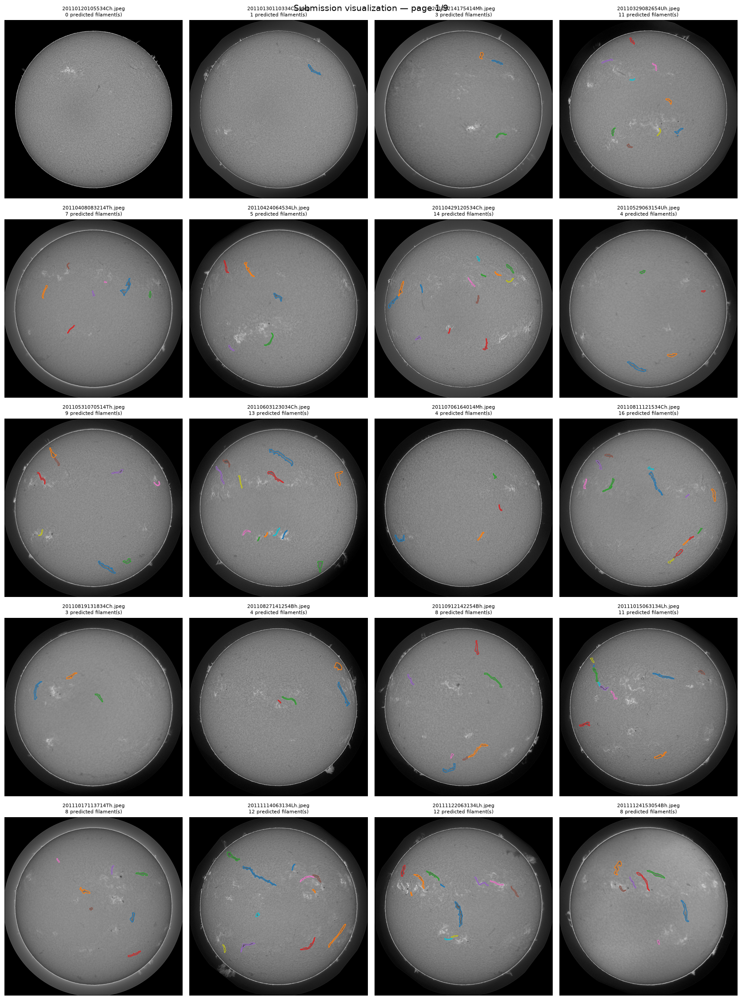

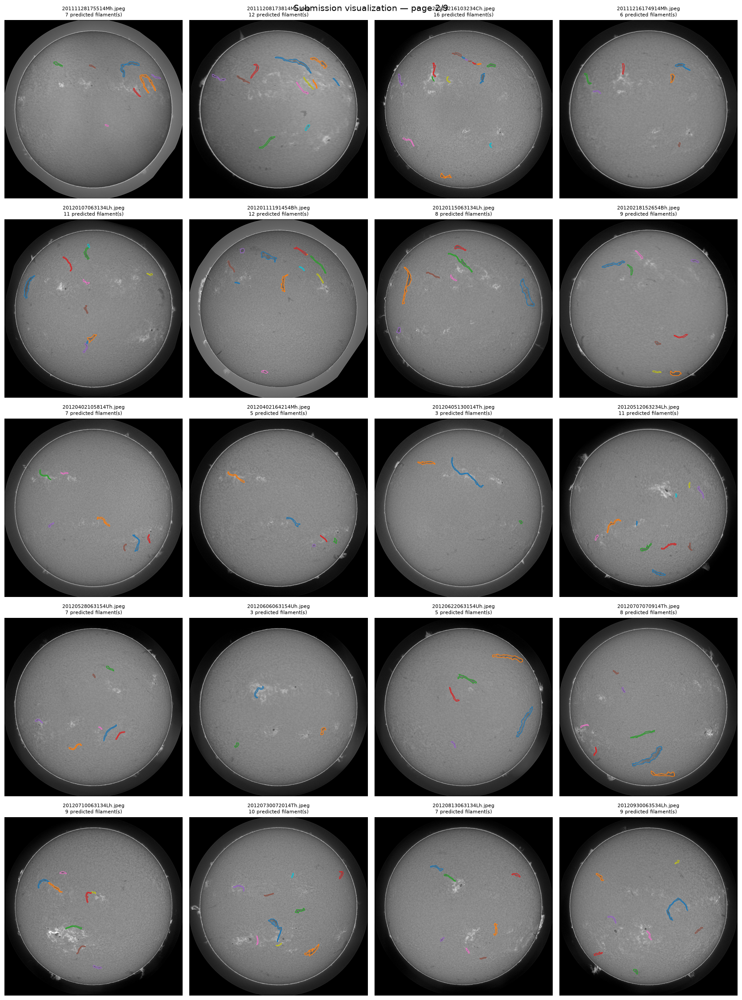

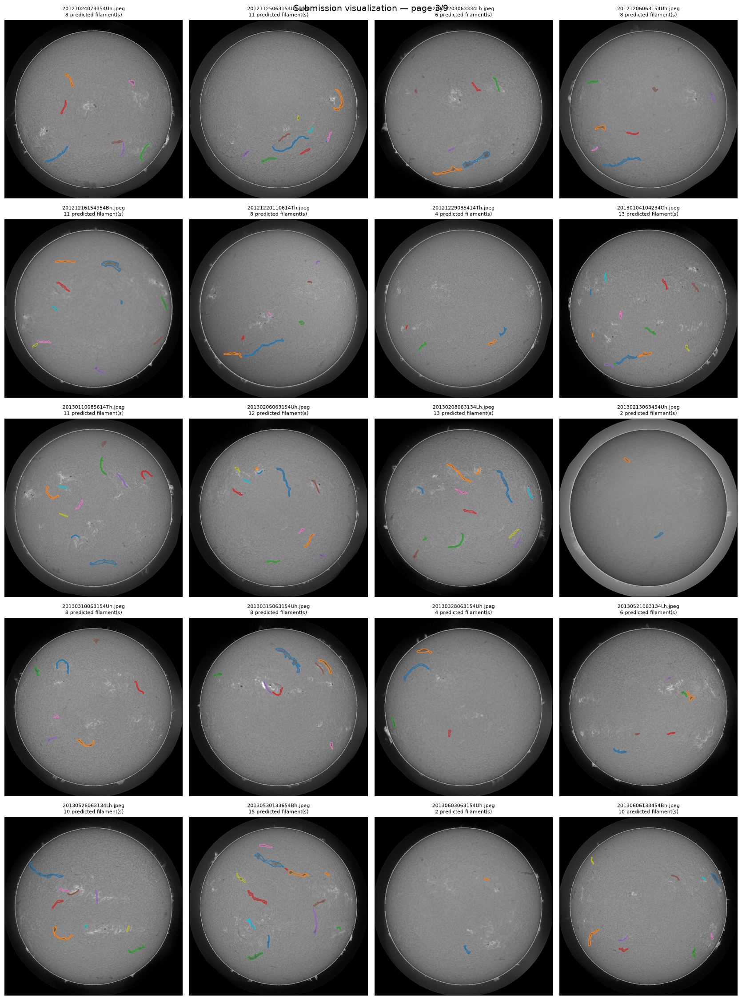

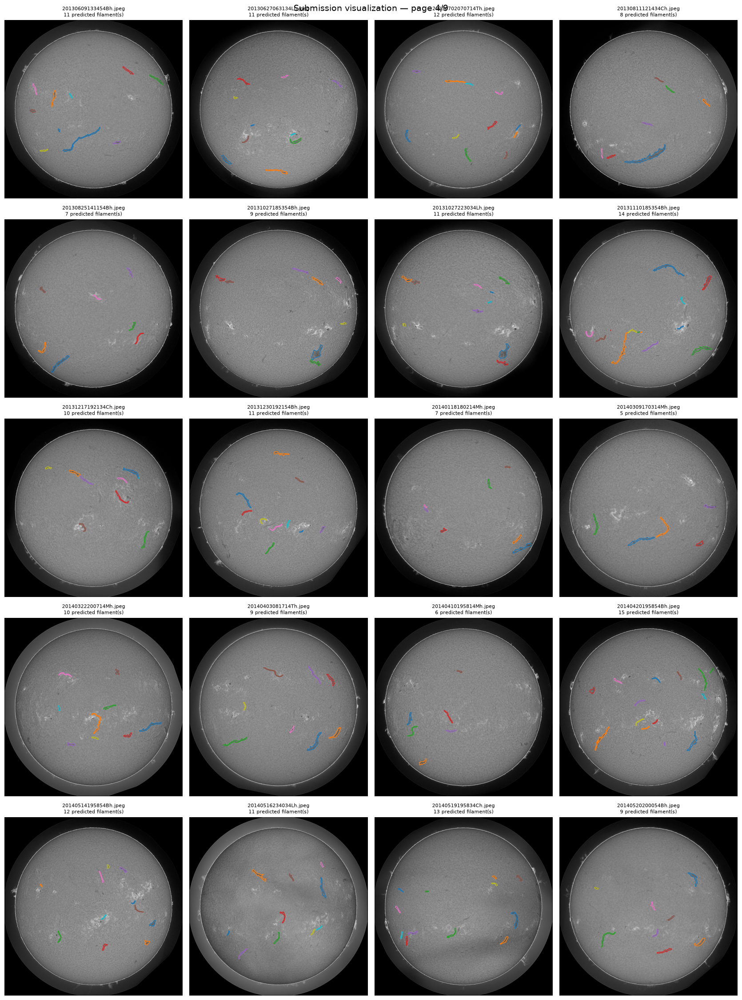

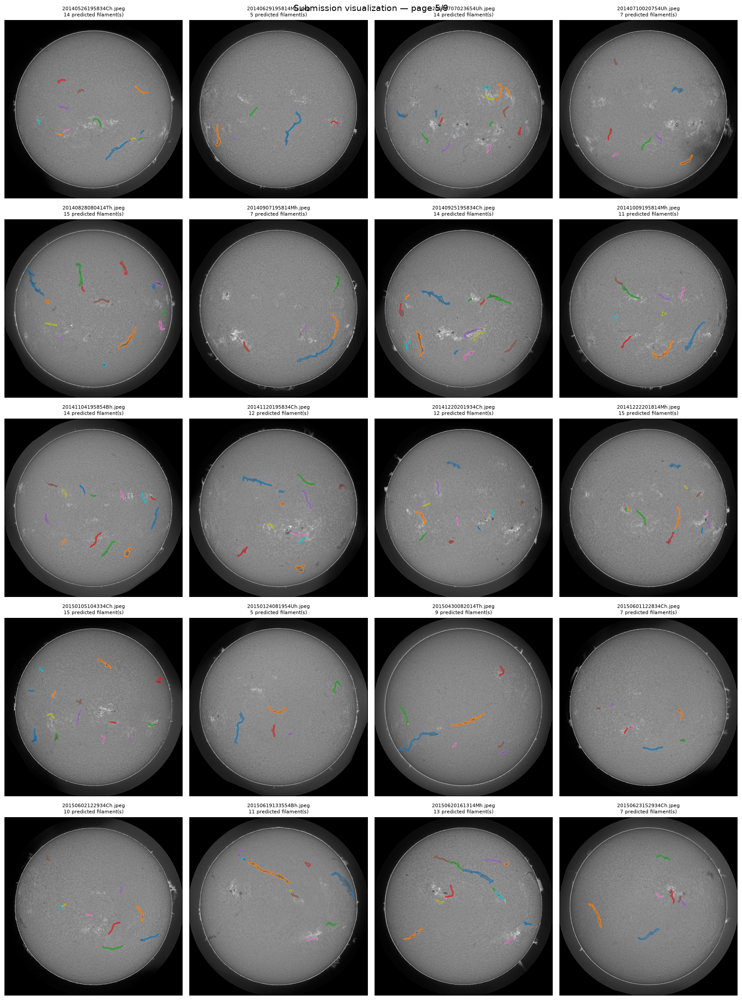

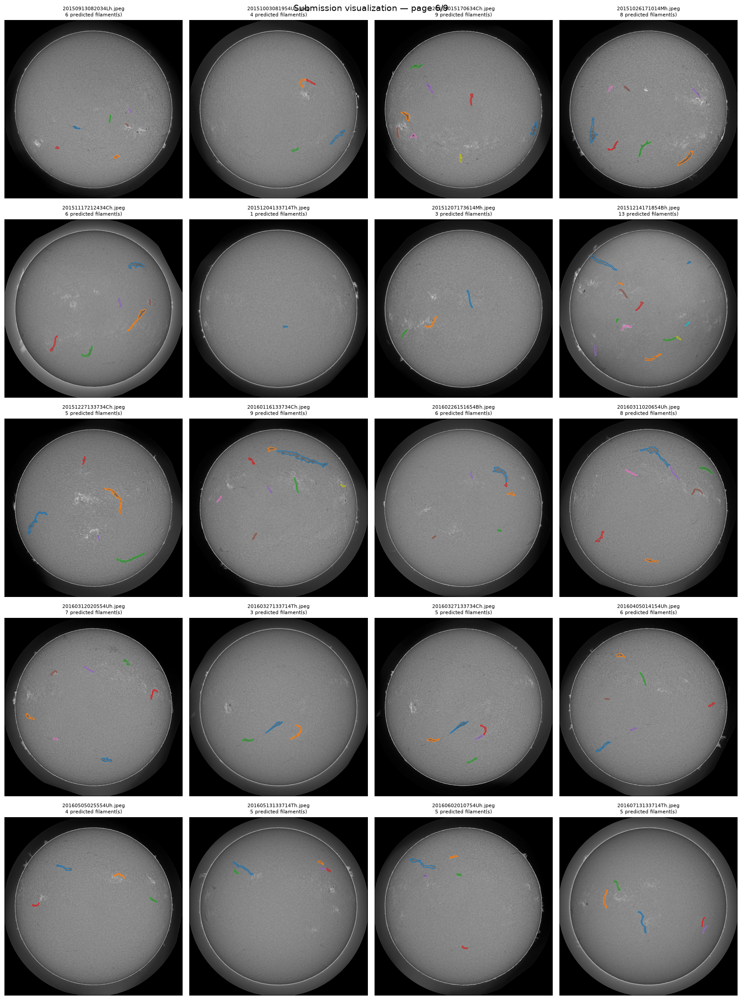

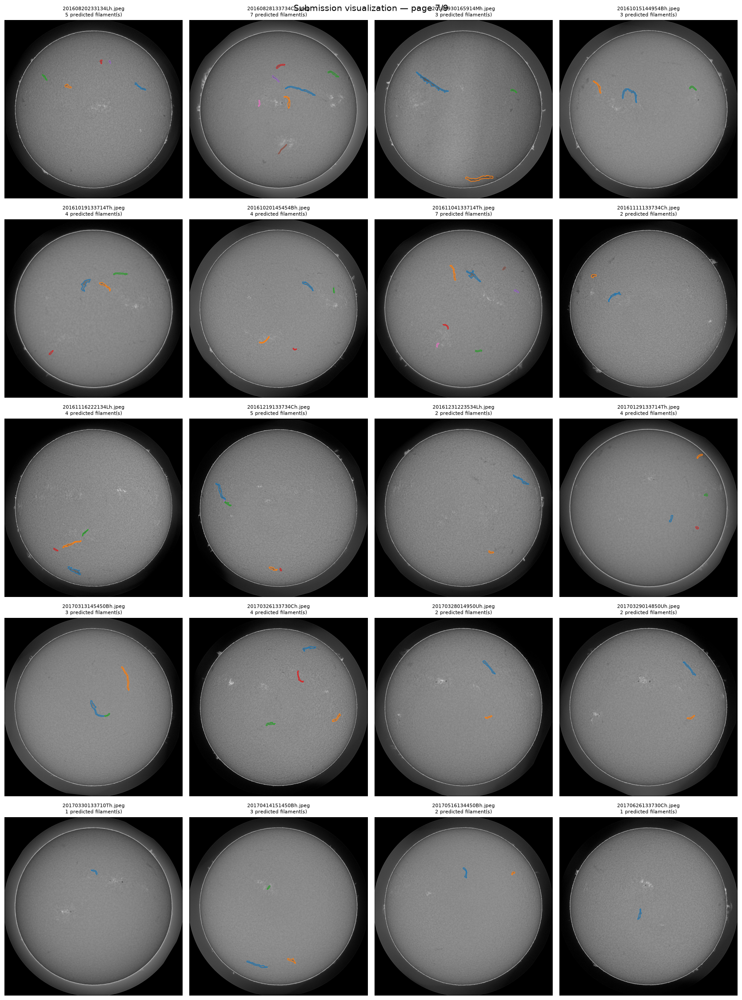

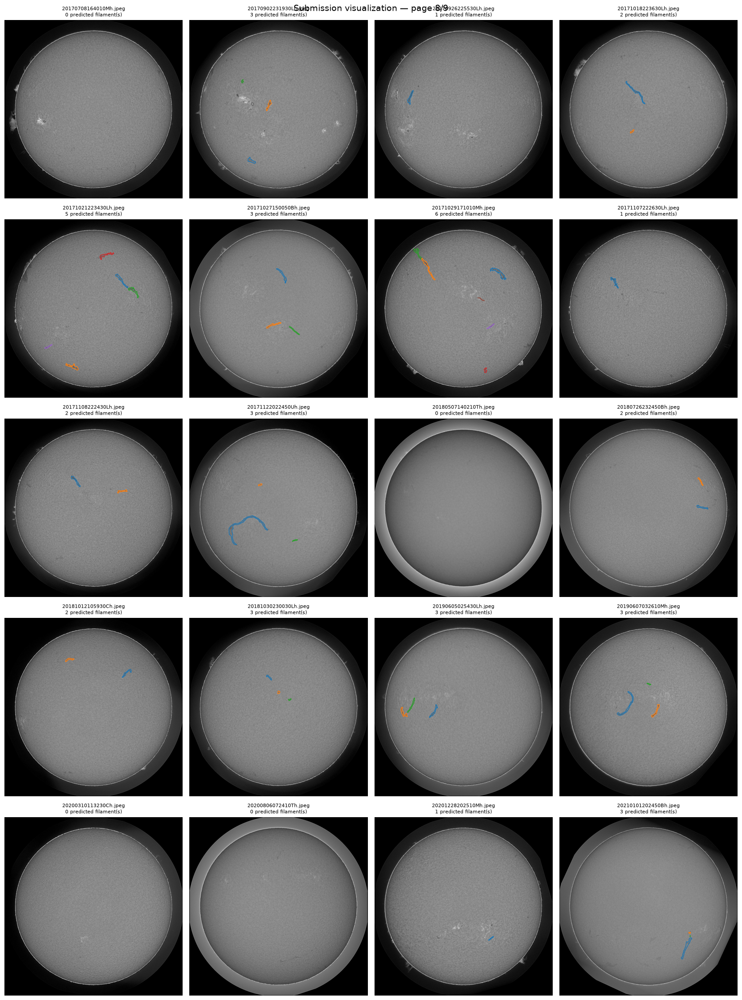

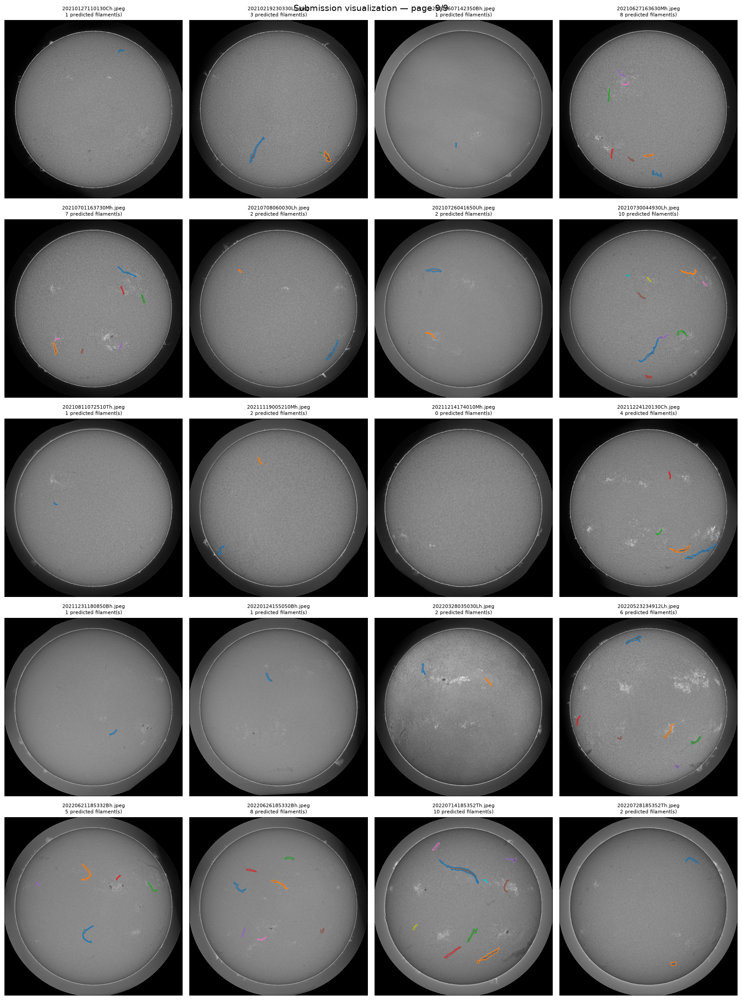

In [8]:
def display_submission_pages(page_size: int = 20, columns: int = 4) -> None:
    """Display every test image with its submitted filament contours, page by page."""
    if page_size <= 0 or columns <= 0:
        raise ValueError("page_size and columns must be positive integers")

    image_ids = list(image_paths)
    page_count = math.ceil(len(image_ids) / page_size)
    rows = math.ceil(page_size / columns)
    colors = plt.cm.tab10(np.linspace(0, 1, 10))

    for page_number, start in enumerate(range(0, len(image_ids), page_size), start=1):
        page_ids = image_ids[start : start + page_size]
        figure, axes = plt.subplots(
            rows,
            columns,
            figsize=(4.2 * columns, 4.6 * rows),
            squeeze=False,
        )
        axes_flat = axes.ravel()

        for axis in axes_flat:
            axis.axis("off")

        for axis, image_id in zip(axes_flat, page_ids):
            image_path = image_paths[image_id]
            image = np.asarray(Image.open(image_path).convert("L"))
            axis.imshow(image, cmap="gray", vmin=0, vmax=255)
            masks = masks_by_image[image_id]
            for instance_index, mask in enumerate(masks):
                if mask.any():
                    axis.contour(mask, levels=[0.5], colors=[colors[instance_index % len(colors)]], linewidths=1.0)
            axis.set_title(f"{image_path.name}\n{len(masks)} predicted filament(s)", fontsize=8)
            axis.axis("off")

        figure.suptitle(f"Submission visualization — page {page_number}/{page_count}", fontsize=14)
        figure.tight_layout()
        plt.show()
        plt.close(figure)


# This renders all images in nine manageable pages.
display_submission_pages(page_size=20, columns=4)
